# Exploratory data analysis: skill positions on 2021 dropbacks (Weeks 1–8)

The challenge asks for an insight about **TEs, WRs and RBs**, so this EDA looks at the data from the route runner's point of view:

1. What the data contains, and its gaps
2. Who runs routes, from where, and how often TEs and RBs stay in to block
3. Who gets targeted, and what happens on those targets
4. Separation at the throw, measured from tracking
5. Man coverage: which defenders end up on TEs and RBs (background for `plan.md`)
6. Player leaderboards
7. Data-quality notes and takeaways

Run from the repo root. The tracking summary is built once by `eda_tracking.py` (about 10 seconds) and cached in `cache/eda_routes.pkl`.

In [1]:
import re
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from eda_tracking import build_routes

sns.set_theme(style="whitegrid")
pd.set_option("display.width", 140, "display.max_columns", 30, "display.precision", 3)
SKILL = ["WR", "TE", "RB"]
PAL = {"WR": "#4C72B0", "TE": "#DD8452", "RB": "#55A868"}

games = pd.read_csv("data/games.csv")
plays = pd.read_csv("data/plays.csv")
players = pd.read_csv("data/players.csv")
scout = pd.read_csv("data/pffScoutingData.csv")
pos = players.set_index("nflId")[["officialPosition", "displayName"]]

## 1. What's in the data

In [2]:
pd.DataFrame({
    "rows": [len(games), len(plays), len(players), len(scout)],
    "columns": [games.shape[1], plays.shape[1], players.shape[1], scout.shape[1]],
    "key": ["gameId", "gameId + playId", "nflId", "gameId + playId + nflId"],
}, index=["games", "plays", "players", "pffScoutingData"])

,rows,columns,key
games,122,7,gameId
plays,8557,32,gameId + playId
players,1679,7,nflId
pffScoutingData,188254,15,gameId + playId + nflId


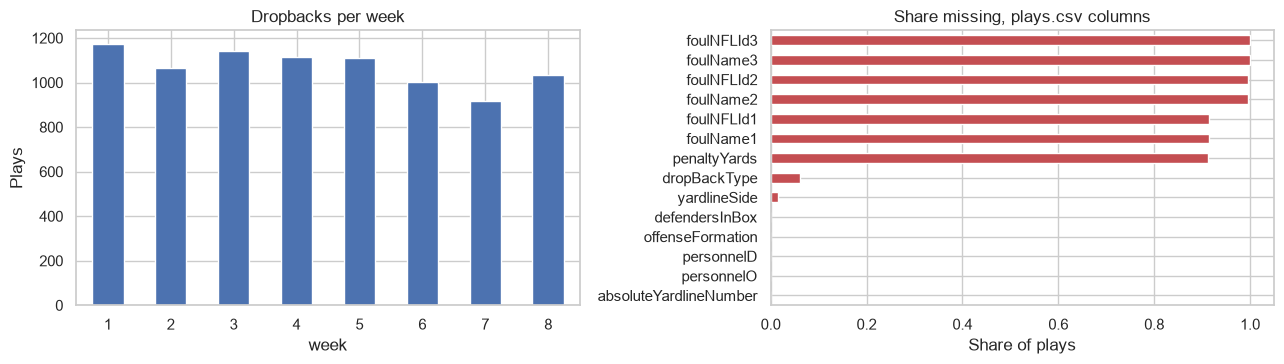

In [3]:
fig, axes = plt.subplots(1, 2, figsize=(13, 3.8))
plays.merge(games, on="gameId").groupby("week").size().plot.bar(ax=axes[0], color="#4C72B0", rot=0)
axes[0].set(title="Dropbacks per week", ylabel="Plays")
miss = plays.isna().mean().loc[lambda s: s > 0].sort_values()
miss.plot.barh(ax=axes[1], color="#C44E52")
axes[1].set(title="Share missing, plays.csv columns", xlabel="Share of plays")
plt.tight_layout()

Every play is a dropback (pass, sack or scramble); there are no designed runs. The penalty and foul columns are mostly empty because most plays have no penalty. There is **no target column and no coverage-assignment column**, so both have to be derived (Sections 3 and 5).

## 2. Who runs routes, and from where

In [4]:
sk = scout.join(pos, on="nflId")
sk = sk[sk.officialPosition.isin(SKILL + ["FB"])]
role = pd.crosstab(sk.officialPosition, sk.pff_role, normalize="index").loc[SKILL + ["FB"]]
role.assign(snaps=sk.officialPosition.value_counts())

pff_role,Coverage,Pass,Pass Block,Pass Route,Pass Rush,snaps
officialPosition,,,,,,
WR,0.000,4.333e-05,0.002,0.998,0.000e+00,23078
TE,0.000,0.000e+00,0.136,0.864,0.000e+00,10496
RB,0.005,0.000e+00,0.181,0.814,5.819e-04,8593
FB,0.000,0.000e+00,0.275,0.725,0.000e+00,531


align,wide,slot,inline,backfield
officialPosition,,,,
WR,0.602,0.393,0.003,0.002
TE,0.147,0.407,0.425,0.020
RB,0.125,0.079,0.010,0.786


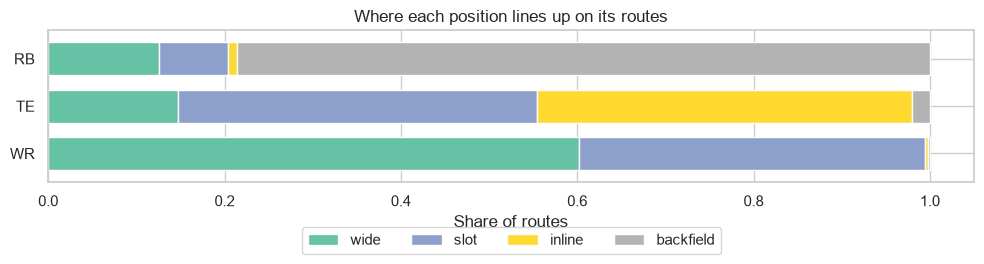

In [5]:
def alignment(a):
    if a.startswith(("HB", "FB")): return "backfield"
    if a.startswith("TE"):         return "inline"
    if a in ("LWR", "RWR"):        return "wide"
    return "slot"

routes_pff = sk[(sk.pff_role == "Pass Route") & sk.officialPosition.isin(SKILL)].copy()
routes_pff["align"] = routes_pff.pff_positionLinedUp.map(alignment)
al = pd.crosstab(routes_pff.officialPosition, routes_pff["align"], normalize="index")[["wide", "slot", "inline", "backfield"]]
ax = al.loc[SKILL].plot.barh(stacked=True, figsize=(10, 3), colormap="Set2", width=0.7)
ax.set(title="Where each position lines up on its routes", xlabel="Share of routes", ylabel="")
ax.legend(ncol=4, loc="upper center", bbox_to_anchor=(0.5, -0.25)); plt.tight_layout()
al.loc[SKILL]

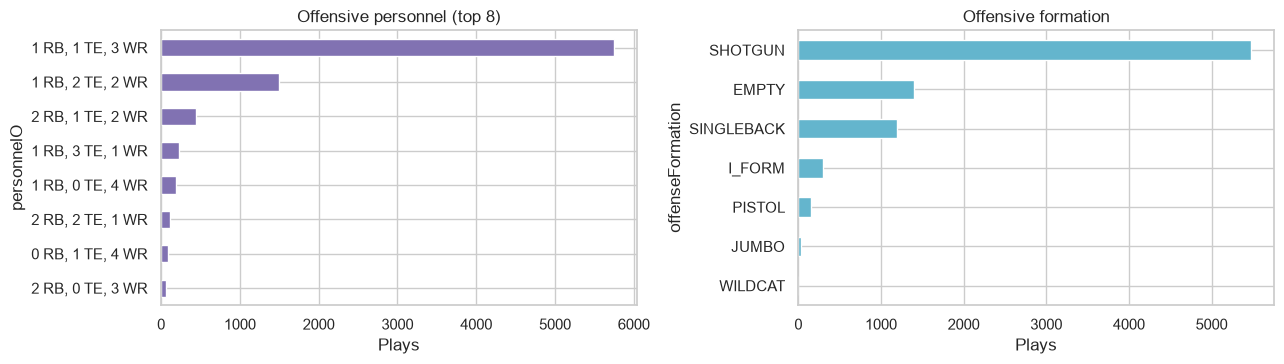

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(13, 3.8))
plays.personnelO.value_counts().head(8).iloc[::-1].plot.barh(ax=axes[0], color="#8172B2")
axes[0].set(title="Offensive personnel (top 8)", xlabel="Plays")
plays.offenseFormation.value_counts().iloc[::-1].plot.barh(ax=axes[1], color="#64B5CD")
axes[1].set(title="Offensive formation", xlabel="Plays")
plt.tight_layout()

## 3. Targets

`plays.csv` has no target column. The intended receiver is parsed from `playDescription` (`"pass short right to C.Godwin"`, `"pass incomplete deep left intended for A.Cooper"`) and matched to a route runner on the same play by first initial and last name.

In [7]:
# Description names look like "C.Godwin", "Mi.Carter" (extra letter when a team has two M.Carters),
# "A.St. Brown" or "C.Edwards-Helaire". Players.csv uses "A.J. Brown", "Odell Beckham Jr.".
# Match on first initial + last name with punctuation and suffixes removed.
pat = r"pass (?:incomplete )?(?:short|deep)? ?(?:left|middle|right)? ?(?:to|intended for) ([A-Z][a-z]?\.(?:St\. )?[A-Z][A-Za-z'\-]+)"
key = lambda first, last: first.str[0] + "|" + last.str.replace(r"[^A-Za-z]", "", regex=True).str.lower()
tok = plays.playDescription.str.extract(pat)[0].str.split(".", n=1)
plays["tgt_abbr"] = key(tok.str[0], tok.str[1])
nm = players.displayName.str.replace(r" (Jr|Sr|II|III|IV)\.?$", "", regex=True)
nm = nm.str.replace(r"^((?:[A-Z]\.)+) ?", lambda m: m.group(1).replace(".", "") + " ", regex=True)  # "A.J. Brown" -> "AJ Brown"
parts = nm.str.split(n=1)
players["abbr"] = key(parts.str[0], parts.str[1])

rr = scout[scout.pff_role == "Pass Route"][["gameId", "playId", "nflId"]].merge(players[["nflId", "abbr"]], on="nflId")
tgt = (plays.dropna(subset=["tgt_abbr"])
       .merge(rr, left_on=["gameId", "playId", "tgt_abbr"], right_on=["gameId", "playId", "abbr"])
       .drop_duplicates(["gameId", "playId"])[["gameId", "playId", "nflId"]].assign(targeted=1))

attempts = plays.passResult.isin(["C", "I", "IN"]).sum()
named = (plays.passResult.isin(["C", "I", "IN"]) & plays.tgt_abbr.notna()).sum()
print(f"Targets matched: {len(tgt):,} of {attempts:,} pass attempts ({len(tgt) / attempts:.1%})")
print(f"  {len(tgt) / named:.1%} of the {named:,} attempts whose description names a receiver; "
      "the rest read like 'pass incomplete short right.'")

Targets matched: 7,288 of 7,565 pass attempts (96.3%)
  99.7% of the 7,308 attempts whose description names a receiver; the rest read like 'pass incomplete short right.'


In [8]:
r3 = routes_pff.merge(tgt, on=["gameId", "playId", "nflId"], how="left").fillna({"targeted": 0})
r3 = r3.merge(plays[["gameId", "playId", "passResult", "playResult", "pff_passCoverageType"]], on=["gameId", "playId"])
t3 = r3[r3.targeted == 1]
summary = pd.DataFrame({
    "routes": r3.groupby("officialPosition").size(),
    "targets": t3.groupby("officialPosition").size(),
    "target_rate": r3.groupby("officialPosition").targeted.mean(),
    "completion": t3.groupby("officialPosition").passResult.apply(lambda s: (s == "C").mean()),
    "int_rate": t3.groupby("officialPosition").passResult.apply(lambda s: (s == "IN").mean()),
    "yds_per_target": t3.groupby("officialPosition").playResult.mean(),
    "yds_per_catch": t3[t3.passResult == "C"].groupby("officialPosition").playResult.mean(),
}).loc[SKILL]
summary

,routes,targets,target_rate,completion,int_rate,yds_per_target,yds_per_catch
officialPosition,,,,,,,
WR,23033,4431,0.192,0.584,0.031,8.461,13.596
TE,9064,1568,0.173,0.668,0.023,7.257,10.560
RB,6994,1227,0.175,0.751,0.007,5.853,7.685


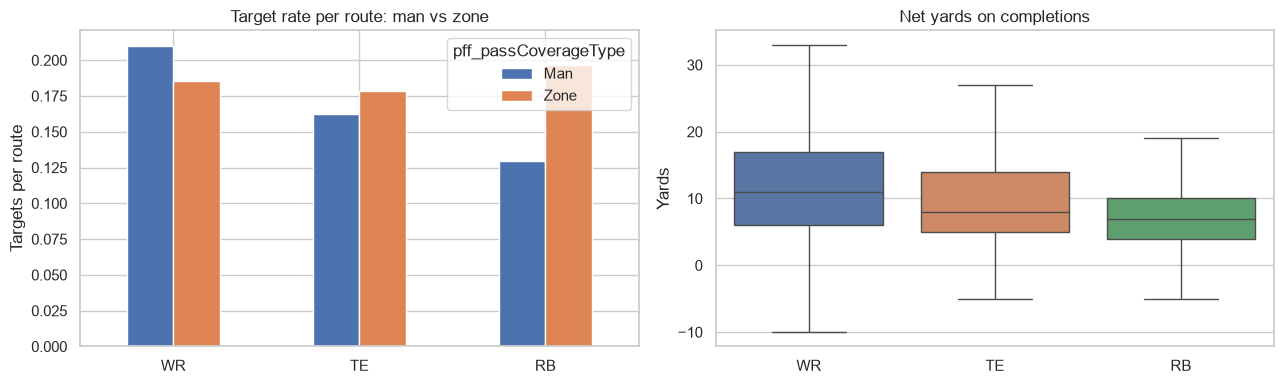

In [9]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
cov = r3[r3.pff_passCoverageType.isin(["Man", "Zone"])]
cov.groupby(["officialPosition", "pff_passCoverageType"]).targeted.mean().unstack().loc[SKILL].plot.bar(ax=axes[0], rot=0)
axes[0].set(title="Target rate per route: man vs zone", ylabel="Targets per route", xlabel="")
sns.boxplot(data=t3[t3.passResult == "C"], x="officialPosition", y="playResult", order=SKILL,
            hue="officialPosition", palette=PAL, showfliers=False, ax=axes[1], legend=False)
axes[1].set(title="Net yards on completions", xlabel="", ylabel="Yards")
plt.tight_layout()

## 4. Separation at the throw (tracking)

For every route, `eda_tracking.py` finds the end of the pass-play window (first `pass_forward`, `autoevent_passforward`, `qb_sack`, `qb_strip_sack` or `run` after the snap) and measures:

- `sep`: distance to the nearest PFF coverage defender, in yards
- `depth`: yards past the line of scrimmage (coordinates normalized so offense moves right)
- `s`: receiver speed, yards/second
- `ttt`: time from snap to the end of the window, seconds

Tracking stops at the throw, so separation at the catch point and yards after catch can't be measured.

In [10]:
routes = build_routes(scout).join(pos, on="nflId")
routes = routes.merge(tgt, on=["gameId", "playId", "nflId"], how="left").fillna({"targeted": 0})
routes = routes.merge(plays[["gameId", "playId", "passResult", "playResult", "pff_passCoverageType", "down", "yardsToGo"]],
                      on=["gameId", "playId"])
routes = routes.merge(scout[["gameId", "playId", "nflId", "pff_positionLinedUp"]], on=["gameId", "playId", "nflId"])
routes["align"] = routes.pff_positionLinedUp.map(alignment)
routes["dpos"] = routes.defId.map(pos.officialPosition)
routes = routes[routes.officialPosition.isin(SKILL)]
print(f"{len(routes):,} skill-position routes on {routes.groupby(['gameId', 'playId']).ngroups:,} plays")
routes.groupby("officialPosition")[["sep", "depth", "s", "ttt"]].median().loc[SKILL]

38,976 skill-position routes on 8,533 plays


,sep,depth,s,ttt
officialPosition,,,,
WR,2.471,8.95,6.12,2.8
TE,2.570,5.72,5.55,2.8
RB,5.829,-0.20,4.91,2.8


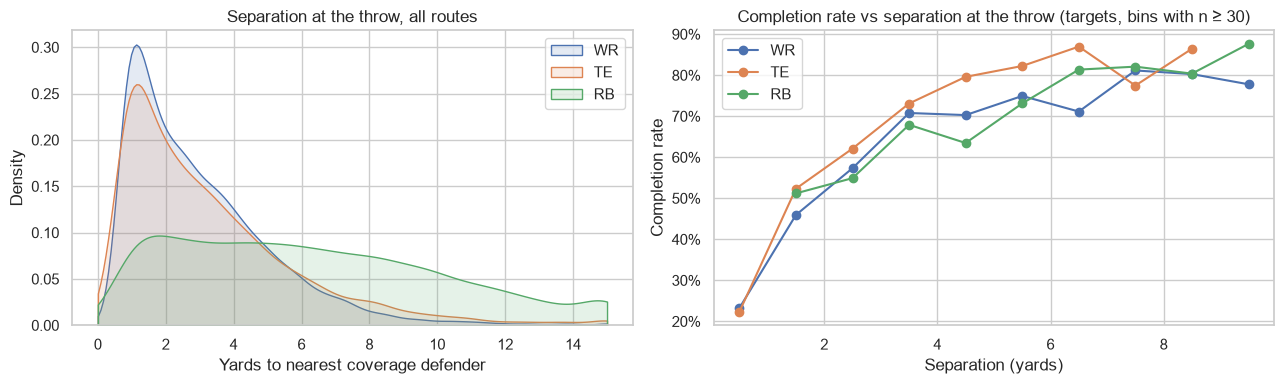

In [11]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
for p in SKILL:
    sns.kdeplot(routes.loc[routes.officialPosition == p, "sep"].clip(upper=15), ax=axes[0], label=p, color=PAL[p], fill=True, alpha=0.15, clip=(0, 15))
axes[0].set(title="Separation at the throw, all routes", xlabel="Yards to nearest coverage defender"); axes[0].legend()

tt = routes[(routes.targeted == 1) & routes.passResult.isin(["C", "I", "IN"])].copy()
tt["bin"] = pd.cut(tt.sep, np.arange(0, 10.5, 1))
curve = tt.groupby(["officialPosition", "bin"], observed=True).agg(comp=("passResult", lambda s: (s == "C").mean()), n=("sep", "size")).reset_index()
curve = curve[curve.n >= 30]
curve["mid"] = curve.bin.apply(lambda b: b.mid)
for p in SKILL:
    c = curve[curve.officialPosition == p]
    axes[1].plot(c.mid, c.comp, marker="o", label=p, color=PAL[p])
axes[1].yaxis.set_major_formatter(plt.matplotlib.ticker.PercentFormatter(1))
axes[1].set(title="Completion rate vs separation at the throw (targets, bins with n ≥ 30)", xlabel="Separation (yards)", ylabel="Completion rate")
axes[1].legend(); plt.tight_layout()

In [12]:
tt.groupby(pd.cut(tt.sep, [0, 1, 2, 3, 5, 8, 60]), observed=True).agg(
    targets=("sep", "size"),
    completion=("passResult", lambda s: (s == "C").mean()),
    int_rate=("passResult", lambda s: (s == "IN").mean()),
    yds=("playResult", "mean"))

,targets,completion,int_rate,yds
sep,,,,
"(0, 1]",599,0.232,0.035,4.980
"(1, 2]",1490,0.475,0.029,7.951
"(2, 3]",1136,0.582,0.039,8.147
"(3, 5]",1827,0.713,0.025,8.369
"(5, 8]",1345,0.777,0.018,7.935
"(8, 60]",808,0.850,0.006,7.236


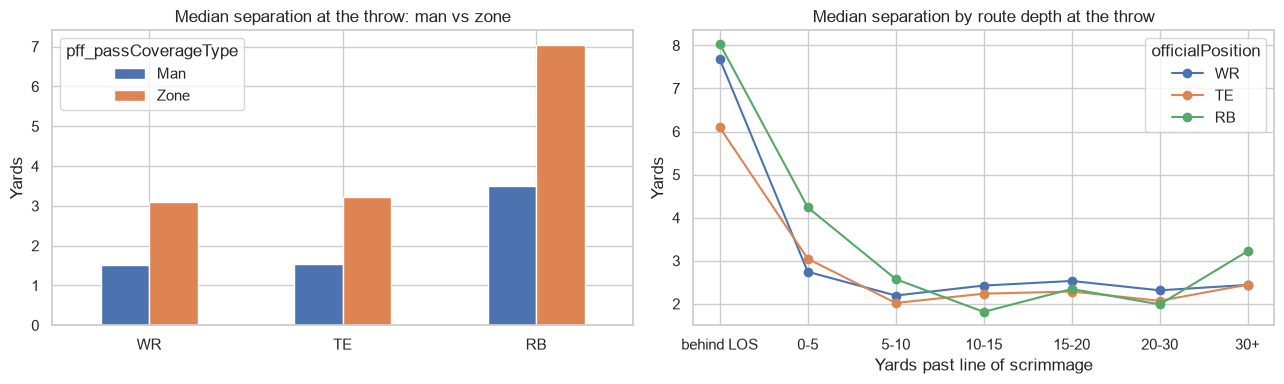

In [13]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
mz = routes[routes.pff_passCoverageType.isin(["Man", "Zone"])]
mz.groupby(["officialPosition", "pff_passCoverageType"]).sep.median().unstack().loc[SKILL].plot.bar(ax=axes[0], rot=0)
axes[0].set(title="Median separation at the throw: man vs zone", ylabel="Yards", xlabel="")

routes["dbin"] = pd.cut(routes.depth, [-15, 0, 5, 10, 15, 20, 30, 60], labels=["behind LOS", "0-5", "5-10", "10-15", "15-20", "20-30", "30+"])
d = routes.groupby(["dbin", "officialPosition"], observed=True).sep.median().unstack()[SKILL]
d.plot(ax=axes[1], marker="o", color=[PAL[p] for p in SKILL])
axes[1].set(title="Median separation by route depth at the throw", xlabel="Yards past line of scrimmage", ylabel="Yards")
plt.tight_layout()

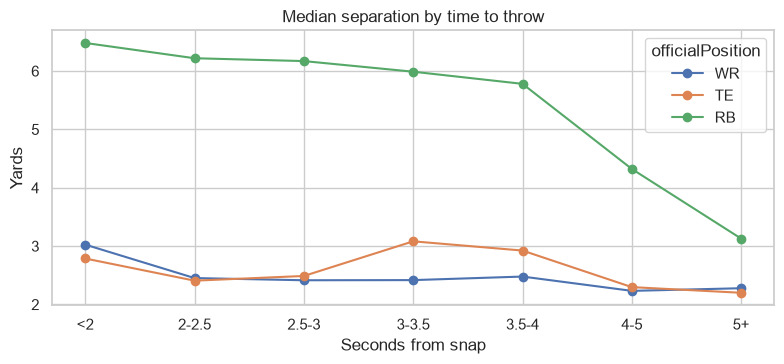

In [14]:
routes["tbin"] = pd.cut(routes.ttt, [0, 2, 2.5, 3, 3.5, 4, 5, 30], labels=["<2", "2-2.5", "2.5-3", "3-3.5", "3.5-4", "4-5", "5+"])
ax = routes.groupby(["tbin", "officialPosition"], observed=True).sep.median().unstack()[SKILL].plot(
    marker="o", figsize=(8, 3.8), color=[PAL[p] for p in SKILL])
ax.set(title="Median separation by time to throw", xlabel="Seconds from snap", ylabel="Yards"); plt.tight_layout()

## 5. Man coverage: who ends up on TEs and RBs?

This is background for `plan.md`. It uses a quick proxy, the **nearest** coverage defender at the throw. The plan uses a stronger method (Hungarian assignment over the whole snap-to-throw window), so its checkpoint numbers will differ from these.

In [15]:
def defender_group(p):
    if p in ("ILB", "OLB", "MLB", "LB"): return "LB"
    if p in ("CB", "FS", "SS", "DB"):    return "DB"
    return "other"

man = routes[routes.pff_passCoverageType == "Man"].copy()
man["dgrp"] = man.dpos.map(defender_group)
lb_rate = (man[man.dgrp != "other"].groupby(["officialPosition", "align"])
           .agg(routes=("sep", "size"), lb_rate=("dgrp", lambda s: (s == "LB").mean())))
lb_rate.loc[["TE", "RB", "WR"]]

routes  lb_rate
officialPosition align                     
TE               backfield      44    0.523
                 inline        966    0.344
                 slot         1113    0.228
                 wide          432    0.150
RB               backfield    1418    0.780
                 inline         25    0.440
                 slot          147    0.551
                 wide          251    0.490
WR               backfield      15    0.333
                 inline         28    0.214
                 slot         2735    0.052
                 wide         4004    0.023

size  median   mean
officialPosition dgrp                     
RB               DB     520   4.519  5.066
                 LB    1321   3.322  4.031
TE               DB    1881   1.479  2.123
                 LB     674   1.722  2.331

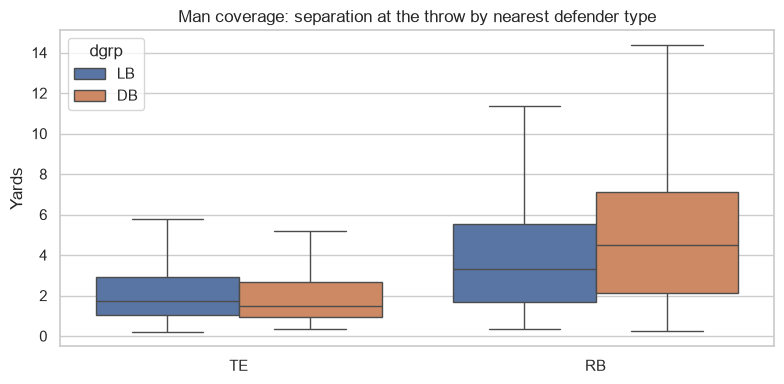

In [16]:
mm = man[man.officialPosition.isin(["TE", "RB"]) & (man.dgrp != "other")]
fig, ax = plt.subplots(figsize=(8, 4))
sns.boxplot(data=mm, x="officialPosition", y="sep", hue="dgrp", showfliers=False, ax=ax, order=["TE", "RB"])
ax.set(title="Man coverage: separation at the throw by nearest defender type", xlabel="", ylabel="Yards")
plt.tight_layout()
mm.groupby(["officialPosition", "dgrp"]).sep.agg(["size", "median", "mean"])

## 6. Player leaderboards

`open_rate` is the share of a player's routes where he is 3+ yards from the nearest defender at the throw, counted on every route, targeted or not. Players need at least 100 routes.

In [17]:
pl = routes.groupby(["nflId", "displayName", "officialPosition"]).agg(
    routes=("sep", "size"), targets=("targeted", "sum"), median_sep=("sep", "median"),
    open_rate=("sep", lambda s: (s >= 3).mean()), avg_depth=("depth", "mean")).reset_index()
pl["target_rate"] = pl.targets / pl.routes
q = pl[pl.routes >= 100]
print(f"{len(q)} qualified players:", q.officialPosition.value_counts().to_dict())
for p in SKILL:
    print(f"\n{p}: highest open rate")
    print(q[q.officialPosition == p].nlargest(8, "open_rate")
          [["displayName", "routes", "targets", "target_rate", "open_rate", "median_sep", "avg_depth"]]
          .set_index("displayName").round(2).to_string())

172 qualified players: {'WR': 103, 'TE': 41, 'RB': 28}

WR: highest open rate
                 routes  targets  target_rate  open_rate  median_sep  avg_depth
displayName                                                                    
Rondale Moore       110     14.0         0.13       0.65        4.22       6.06
Marquise Brown      234     48.0         0.21       0.55        3.25      12.61
Michael Pittman     249     59.0         0.24       0.55        3.21       9.09
Jaylen Waddle       269     53.0         0.20       0.53        3.16       8.35
Mecole Hardman      232     34.0         0.15       0.51        3.06      10.93
Cooper Kupp         239     84.0         0.35       0.50        3.02       7.56
Tyler Lockett       216     54.0         0.25       0.50        2.95      11.72
Kendall Hinton      101     16.0         0.16       0.50        2.98       8.53

TE: highest open rate
                 routes  targets  target_rate  open_rate  median_sep  avg_depth
displayName        

correlation by position: {'WR': np.float64(-0.03), 'TE': np.float64(-0.35), 'RB': np.float64(-0.32)}


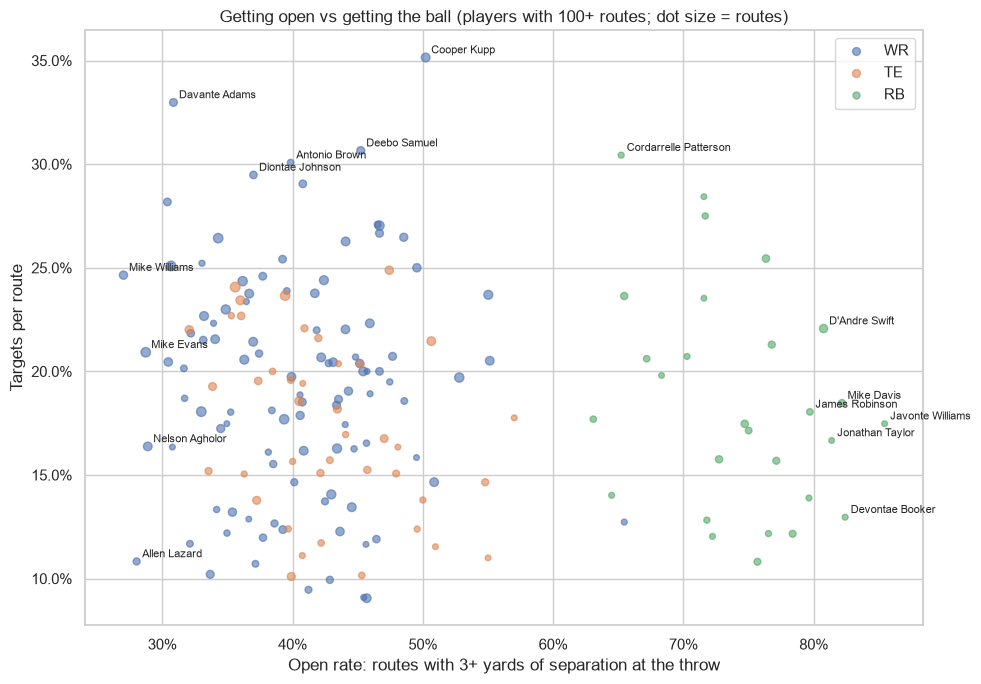

In [18]:
fig, ax = plt.subplots(figsize=(10, 7))
for p in SKILL:
    d = q[q.officialPosition == p]
    ax.scatter(d.open_rate, d.target_rate, s=d.routes / 6, alpha=0.6, label=p, color=PAL[p])
lab = pd.concat([q.nlargest(6, "target_rate"), q.nlargest(6, "open_rate"),
                 q[q.officialPosition == "WR"].nsmallest(4, "open_rate")]).drop_duplicates("nflId")
for _, r in lab.iterrows():
    ax.annotate(r.displayName, (r.open_rate, r.target_rate), xytext=(4, 3), textcoords="offset points", fontsize=8)
ax.xaxis.set_major_formatter(plt.matplotlib.ticker.PercentFormatter(1))
ax.yaxis.set_major_formatter(plt.matplotlib.ticker.PercentFormatter(1))
ax.set(title="Getting open vs getting the ball (players with 100+ routes; dot size = routes)",
       xlabel="Open rate: routes with 3+ yards of separation at the throw", ylabel="Targets per route")
ax.legend(); plt.tight_layout()
print("correlation by position:", {p: round(q[q.officialPosition == p][["open_rate", "target_rate"]].corr().iloc[0, 1], 2) for p in SKILL})

## 7. Data-quality notes

In [19]:
raw = scout[scout.pff_role == "Pass Route"]
all_routes = build_routes(scout)
print(f"Route rows in PFF data:                 {len(raw):,}")
print(f"Routes with a tracking window:          {len(all_routes):,} ({len(all_routes) / len(raw):.1%})")
print(f"Plays with a tracking window:           {all_routes.groupby(['gameId', 'playId']).ngroups:,} of {len(plays):,}")
print(f"Targets parsed from description:        {len(tgt) / attempts:.1%} of pass attempts")
print(f"Windows longer than 5 s (scrambles):    {(all_routes.drop_duplicates(['gameId', 'playId']).ttt > 5).mean():.1%} of plays")
print("Window end event:", all_routes.drop_duplicates(["gameId", "playId"]).end_event.value_counts().to_dict())

Route rows in PFF data:                 39,513
Routes with a tracking window:          39,398 (99.7%)
Plays with a tracking window:           8,533 of 8,557
Targets parsed from description:        96.3% of pass attempts
Windows longer than 5 s (scrambles):    7.0% of plays
Window end event: {'pass_forward': 4826, 'autoevent_passforward': 2743, 'run': 467, 'qb_sack': 446, 'qb_strip_sack': 51}


- Untagged `event` values are the string `"None"` in some tracking files and empty (NaN) in others. `eda_tracking.py` fills NaN with `"None"`.
- Snap and throw tags come in two versions (`ball_snap` / `autoevent_ballsnap`, `pass_forward` / `autoevent_passforward`). Both count; the earlier one is used.
- "Nearest defender" is a proxy for coverage. In zone, the nearest defender may not be responsible for that receiver.
- Eight weeks gives roughly 100–350 routes per regular player and fewer targets, so small differences between individual players are noisy.

## 8. Takeaways

**Usage**
- TEs stay in to pass block on 13.6% of their dropback snaps and RBs on 18.1%. WRs almost never block (0.2%).
- TEs are split between inline (43%) and slot (41%) alignments. RBs line up in the backfield on 79% of their routes.
- WRs get the most targets per route (19.2%), but RBs (17.5%) and TEs (17.3%) are close behind. RBs catch the most (75% completion, 0.7% interceptions) and gain the fewest yards per catch (7.7).
- Against man coverage, RBs are targeted much less often (12.9% of routes vs 19.6% against zone). WRs are targeted slightly more (21.0% vs 18.6%).

**Separation at the throw**
- Separation drives completion. Completion rate rises from 23% when the receiver is within 1 yard of a defender to 85% at 8+ yards. Throws into a window under 1 yard also average only 5.0 yards, compared with about 8 for every other bucket.
- Man coverage halves separation for WRs and TEs (median about 1.5 yds vs 3.1–3.2 against zone). RBs go from 7.0 to 3.5.
- Past 5 yards downfield, WR and TE separation flattens at about 2–2.5 yds. Most of the open space is at or behind the line of scrimmage.
- WR and TE separation barely changes with time to throw. RB separation collapses after 4 seconds, when defenders rally to the checkdown.

**Man-coverage matchups (nearest-defender proxy)**
- The nearest defender is a linebacker on 78% of backfield RB routes, 34% of inline TE routes and 15% of wide TE routes.
- TEs have more space when the nearest defender is a linebacker (median 1.72 yds) than when it is a defensive back (1.48). This is the gap `plan.md` builds on. The plan's Hungarian matching should give a cleaner estimate.

**Players**
- For TEs and RBs, being open is *negatively* correlated with being targeted (r = −0.35 and −0.32). The most-open TEs (Ryan Griffin, Will Dissly, Dawson Knox) are low-volume players that defenses leave alone, while featured TEs are covered tightly. For WRs there is no relationship (r = −0.03).
- High-target WRs such as Davante Adams and Mike Williams are open on only about 30% of routes. Cooper Kupp leads all players at 35% targets per route while being open on 50% of routes.

**Limits.** Tracking ends at the throw, so there is no catch-point separation or yards after catch. "Nearest defender" is not the same as "assigned defender", especially in zone. Weeks 1–8 give about 100–270 routes per qualified player.